<a href="https://colab.research.google.com/github/AlhanoufIB/2026-GP1-26/blob/main/Mullak_Heatmap_Data_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mullak (مُلّاك) — Heat map data preparation
Cleans the **RCRC Open Data Portal** dataset and the **Suhail** dataset, integrates them into one table, and exports the file the app's heat map reads.

**Run the cells from top to bottom** (Runtime → Run all works too). Each step prints what it did, so you can copy the numbers into the report (section 4.4.3 / data preprocessing).

| Output file | What it is |
|---|---|
| `mullak_locations_integrated.csv` | Full cleaned + integrated table (for the report and the Release 2 models) |
| `heatmap_points.json` | Small file for the Flutter heat map (one point per commercial location) |
| `district_features.csv` | One row per district: commercial activity + market indicators (input for the Release 2 models) |

## Step 1 — Upload the two dataset files
Run this cell and choose **both** files: the Suhail Excel file (5 worksheets) and the RCRC file (Excel or CSV).

In [3]:
import pandas as pd, numpy as np, re, json, io, os
pd.set_option('display.max_columns', 50)

try:
    from google.colab import files
    uploaded = files.upload()          # pick both files
    FILE_NAMES = list(uploaded.keys())
except ImportError:                    # running outside Colab
    FILE_NAMES = [f for f in os.listdir('.') if f.lower().endswith(('.xlsx', '.xls', '.csv'))]
print('Files:', FILE_NAMES)

Saving QI_Neighborhood_Data.xlsx to QI_Neighborhood_Data (1).xlsx
Saving commercial-services-by-category-sub-municipality-and-district-2024.xlsx to commercial-services-by-category-sub-municipality-and-district-2024.xlsx
Files: ['QI_Neighborhood_Data (1).xlsx', 'commercial-services-by-category-sub-municipality-and-district-2024.xlsx']


## Step 2 — Load the files
The Suhail file is the Excel file with the worksheets *Summary, Parcel Types, Rental Residential, Rental Commercial, Urban Area Status*; the other file is RCRC. The cell detects which is which.

In [4]:
def read_any(path, sheet=None):
    if path.lower().endswith('.csv'):
        for enc in ('utf-8-sig', 'utf-8', 'cp1256'):        # cp1256 = Arabic Windows
            for sep in (',', ';'):
                try:
                    df = pd.read_csv(path, encoding=enc, sep=sep)
                    if df.shape[1] > 1:
                        return df
                except Exception:
                    pass
        raise ValueError(f'Could not read {path}')
    return pd.read_excel(path, sheet_name=sheet)

suhail_path, rcrc_path = None, None
for f in FILE_NAMES:
    if f.lower().endswith(('.xlsx', '.xls')):
        sheets = pd.ExcelFile(f).sheet_names
        if any('summary' in s.lower() for s in sheets) and len(sheets) >= 3:
            suhail_path = f
            continue
    rcrc_path = f

print('Suhail file:', suhail_path)
print('RCRC file  :', rcrc_path)
assert suhail_path and rcrc_path, 'Upload both files in Step 1'

suhail_sheets = pd.read_excel(suhail_path, sheet_name=None)   # dict: sheet name -> DataFrame
rcrc_raw = read_any(rcrc_path, sheet=0)

for name, df in suhail_sheets.items():
    print(f'Suhail / {name}: {df.shape[0]} rows x {df.shape[1]} columns')
print(f'RCRC: {rcrc_raw.shape[0]} rows x {rcrc_raw.shape[1]} columns')

Suhail file: QI_Neighborhood_Data (1).xlsx
RCRC file  : commercial-services-by-category-sub-municipality-and-district-2024.xlsx
Suhail / Summary: 3 rows x 29 columns
Suhail / Parcel Types: 39 rows x 13 columns
Suhail / Rental Residential: 15 rows x 10 columns
Suhail / Rental Commercial: 9 rows x 10 columns
Suhail / Urban Area Status: 53 rows x 9 columns
RCRC: 2658 rows x 20 columns


## Step 3 — Helper functions
Column names are matched by meaning (case/spaces ignored), and Arabic district names are normalized so *"حي النرجس"*, *"النرجس"* and *"النرجـس"* all match.

In [5]:
def key(s):
    # 'Geo Point 2D' -> 'geopoint2d'
    return re.sub(r'[^a-z0-9؀-ۿ]', '', str(s).lower())

def col(df, *names, required=True):
    # Find a column by any of its possible names.
    lookup = {key(c): c for c in df.columns}
    for n in names:
        if key(n) in lookup:
            return lookup[key(n)]
    if required:
        raise KeyError(f'None of {names} found. Columns are: {list(df.columns)}')
    return None

AR_DIACRITICS = re.compile(r'[ً-ْـ]')   # tashkeel + tatweel
def norm_district(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    s = AR_DIACRITICS.sub('', s)
    s = re.sub('[إأآا]', 'ا', s).replace('ى', 'ي').replace('ة', 'ه')
    s = re.sub(r'^\s*(حي|district|al-|al\s)\s*', '', s, flags=re.I)
    s = re.sub(r'\s*(district|حي)\s*$', '', s, flags=re.I)
    s = re.sub(r'\s+', ' ', s).strip().lower()
    return s or np.nan

def clean_text(series):
    return (series.astype('string').str.strip()
                  .str.replace(r'\s+', ' ', regex=True)
                  .replace({'': pd.NA, 'nan': pd.NA, 'None': pd.NA, '-': pd.NA, 'غير متوفر': pd.NA}))

print(norm_district('حي النَّرجس'), '|', norm_district('Al Narjis'), '|', norm_district('ظهرة لبن'))

النرجس | narjis | ظهره لبن


## Step 4 — Clean the RCRC dataset
Keeps only rows with valid coordinates inside Riyadh, removes duplicates, trims text, and converts areas to numbers.

In [6]:
r = rcrc_raw.copy()
r.columns = [str(c).strip() for c in r.columns]
report = {'rcrc_raw_rows': len(r)}

C = {
    'id':       col(r, 'Internal Item ID', 'رقم العنصر الداخلي', 'Internal ID', 'ID', required=False),
    'district': col(r, 'District Name', 'اسم الحي', 'District'),
    'district_code': col(r, 'District Code', 'رمز الحي', required=False),
    'submun':   col(r, 'Sub-Municipality Name', 'اسم بلدية فرعية', 'Sub Municipality Name', required=False),
    'sector':   col(r, 'Geographic Sector Name', 'اسم القطاع الجغرافي', required=False),
    'ptype':    col(r, 'Property Type', 'نوع الملكية', required=False),
    'category': col(r, 'Commercial Category', 'الفئة التجارية', 'Commercial Category Name', required=False),
    'total_area':  col(r, 'Total Land Parcel Area (m²)', 'مساحة الاجمالية لقطعة الارض (م2)', 'Total Land Parcel Area', required=False),
    'actual_area': col(r, 'Actual Land Parcel Area (m²)', 'المساحة الفعلية لقطعة الارض (م2)', 'Actual Land Parcel Area', required=False),
    'geo2d':    col(r, 'Geo Point 2D', 'geo_point_2d', required=False),
    'geo':      col(r, 'Geographic Coordinates', 'الإحداثيات الجغرافية', 'Coordinates', required=False),
}
print({k: v for k, v in C.items()})

# 4.1 exact duplicate rows, then duplicate IDs
before = len(r); r = r.drop_duplicates(); report['rcrc_exact_duplicates_removed'] = before - len(r)
if C['id']:
    before = len(r); r = r.drop_duplicates(subset=[C['id']]); report['rcrc_duplicate_ids_removed'] = before - len(r)

# 4.2 coordinates -> lat / lng
def parse_point(v):
    # Accepts '24.81, 46.62', '[24.81, 46.62]', '{"lat":..,"lon":..}', 'POINT (46.62 24.81)'
    if pd.isna(v):
        return (np.nan, np.nan)
    s = str(v)
    nums = [float(n) for n in re.findall(r'-?\d+(?:\.\d+)?', s)]
    if len(nums) < 2:
        return (np.nan, np.nan)
    a, b = nums[0], nums[1]
    # Riyadh: latitude ~24-25, longitude ~46-47 -> put them in the right order
    if 40 <= a <= 60 and 15 <= b <= 35:
        a, b = b, a
    return (a, b)

src = C['geo2d'] or C['geo']
if src is None:
    lat_c = col(r, 'Latitude', 'lat'); lng_c = col(r, 'Longitude', 'lng', 'lon')
    r['lat'] = pd.to_numeric(r[lat_c], errors='coerce'); r['lng'] = pd.to_numeric(r[lng_c], errors='coerce')
else:
    pts = [parse_point(v) for v in r[src]]
    r['lat'] = [p[0] for p in pts]; r['lng'] = [p[1] for p in pts]
    if C['geo2d'] and C['geo']:            # fill gaps from the second column
        miss = r['lat'].isna()
        if miss.any():
            pts2 = [parse_point(v) for v in r.loc[miss, C['geo']]]
            r.loc[miss, 'lat'] = [p[0] for p in pts2]
            r.loc[miss, 'lng'] = [p[1] for p in pts2]

# 4.3 drop missing / outside Riyadh
RIYADH = dict(lat_min=24.2, lat_max=25.3, lng_min=46.2, lng_max=47.4)
report['rcrc_missing_coordinates'] = int(r['lat'].isna().sum())
inside = r['lat'].between(RIYADH['lat_min'], RIYADH['lat_max']) & r['lng'].between(RIYADH['lng_min'], RIYADH['lng_max'])
report['rcrc_outside_riyadh'] = int((~inside & r['lat'].notna()).sum())
r = r[inside].copy()

# 4.4 same location listed twice (same point + same category)
dup_cols = ['lat', 'lng'] + ([C['category']] if C['category'] else [])
before = len(r); r = r.drop_duplicates(subset=dup_cols); report['rcrc_same_point_duplicates_removed'] = before - len(r)

# 4.5 text + numbers
for k in ('district', 'submun', 'sector', 'ptype', 'category'):
    if C[k]:
        r[C[k]] = clean_text(r[C[k]])
for k in ('total_area', 'actual_area'):
    if C[k]:
        r[C[k]] = pd.to_numeric(r[C[k]].astype(str).str.replace(',', ''), errors='coerce')
        bad = r[C[k]] <= 0
        r.loc[bad, C[k]] = np.nan          # area must be > 0
report['rcrc_missing_district'] = int(r[C['district']].isna().sum())
r['district_key'] = r[C['district']].apply(norm_district)

report['rcrc_clean_rows'] = len(r)
for k, v in report.items(): print(f'{k:40s} {v}')
r.head()

{'id': 'رقم العنصر الداخلي', 'district': 'اسم الحي', 'district_code': 'رمز الحي', 'submun': 'اسم بلدية فرعية', 'sector': 'اسم القطاع الجغرافي', 'ptype': 'نوع الملكية', 'category': 'الفئة التجارية', 'total_area': 'مساحة الاجمالية لقطعة الارض (م2)', 'actual_area': 'المساحة الفعلية لقطعة الارض (م2)', 'geo2d': 'geo_point_2d', 'geo': 'الإحداثيات الجغرافية'}
rcrc_raw_rows                            2658
rcrc_exact_duplicates_removed            0
rcrc_duplicate_ids_removed               0
rcrc_missing_coordinates                 0
rcrc_outside_riyadh                      0
rcrc_same_point_duplicates_removed       3
rcrc_missing_district                    7
rcrc_clean_rows                          2655


,رقم العنصر الداخلي,رقم الخدمة,اسم الخدمة,رمز القطاع الجغرافي,اسم القطاع الجغرافي,رمز البلدية الفرعية,اسم بلدية فرعية,رمز الحي,اسم الحي,رمز نوع الملكية,نوع الملكية,رمز مصدر البيانات,مصدر البيانات,رمز الفئة التجارية,الفئة التجارية,مساحة الاجمالية لقطعة الارض (م2),المساحة الفعلية لقطعة الارض (م2),التعليقات,الإحداثيات الجغرافية,geo_point_2d,lat,lng,district_key
0,1,72054130001,فرع شركه العزيزيه بنده المتحده,3,الشرق,7,الروضة,720,إشبيلية,2,خاص,NaN,غير متوفر,MktS,متجر سوق,1014.0,NaN,NaN,"{""coordinates"":[46.80706952,24.80787333],""type...","24.80787333, 46.80706952",24.807873,46.807070,اشبيليه
1,2,71654130002,شركة الدانوب للمواد الغذائية والكماليات,3,الشرق,7,الروضة,716,اليرموك,2,خاص,NaN,غير متوفر,HypMkt,هايبر ماركت,8460.0,NaN,NaN,"{""coordinates"":[46.77068613,24.81190166],""type...","24.81190166, 46.77068613",24.811902,46.770686,اليرموك
2,3,70554130003,شركة متاجر سبار التجارية,3,الشرق,7,الروضة,705,الحمراء,2,خاص,NaN,غير متوفر,SupMkt,سوبر ماركت,1185.0,NaN,NaN,"{""coordinates"":[46.74517494,24.76304233],""type...","24.76304233, 46.74517494",24.763042,46.745175,الحمراء
3,4,70554130004,شركة العزيزيه بنده المتحده,3,الشرق,7,الروضة,705,الحمراء,2,خاص,NaN,غير متوفر,MktS,متجر سوق,999.0,NaN,NaN,"{""coordinates"":[46.7652054,24.79025378],""type""...","24.79025378, 46.7652054",24.790254,46.765205,الحمراء
4,5,71254130005,شركة اسواق عبدالله العثيم,3,الشرق,7,الروضة,712,الأندلس,2,خاص,NaN,غير متوفر,MktS,متجر سوق,3812.0,NaN,NaN,"{""coordinates"":[46.78190685,24.73809667],""type...","24.73809667, 46.78190685",24.738097,46.781907,الاندلس


## Step 5 — Clean the Suhail dataset
One row per neighborhood: the **Summary** sheet plus the commercial rent from **Rental Commercial** (latest period, averaged over unit types).

In [7]:
def sheet(*names):
    for n in suhail_sheets:
        if any(key(x) == key(n) for x in names):
            return suhail_sheets[n].copy()
    raise KeyError(f'Sheet {names} not found: {list(suhail_sheets)}')

s = sheet('Summary')
s.columns = [str(c).strip() for c in s.columns]
s = s.drop_duplicates()
S = {
    'id': col(s, 'Neighborhood ID'),
    'en': col(s, 'District (EN)', 'District EN'),
    'ar': col(s, 'District (AR)', 'District AR'),
}
keep = {
    'avg_price_per_m2':     col(s, 'Avg. Price Per m² (SAR)', 'Avg Price Per m2 (SAR)', required=False),
    'population':           col(s, 'Total Population (2026)', 'Total Population', required=False),
    'population_density':   col(s, 'Population Density (/sq km)', 'Population Density', required=False),
    'density_band':         col(s, 'Density Band', required=False),
    'purchase_power':       col(s, 'Purchase Power (SAR/month)', 'Purchase Power', required=False),
    'income_band':          col(s, 'Income Band', required=False),
    'total_pois':           col(s, 'Total POIs', required=False),
    'parcels_built_pct':    col(s, 'Parcels Built %', required=False),
}
summary = s[[S['id'], S['en'], S['ar']] + [c for c in keep.values() if c]].copy()
summary.columns = ['neighborhood_id', 'district_en', 'district_ar'] + [k for k, c in keep.items() if c]
for c in summary.columns[3:]:
    if summary[c].dtype == object and c not in ('density_band', 'income_band'):
        summary[c] = pd.to_numeric(summary[c].astype(str).str.replace(r'[^\d.\-]', '', regex=True), errors='coerce')

# Rental Commercial: latest period per neighborhood, mean rent/m², total contracts
rc = sheet('Rental Commercial')
rc.columns = [str(c).strip() for c in rc.columns]
rid, rper = col(rc, 'Neighborhood ID'), col(rc, 'Period')
rrent, rcon = col(rc, 'Avg. Rent Per m² (SAR)', 'Avg Rent Per m2 (SAR)'), col(rc, 'Contracts', required=False)
rc[rrent] = pd.to_numeric(rc[rrent], errors='coerce')
rc = rc.dropna(subset=[rrent])
per = rc[rper].astype(str).str.extract(r'(\d{1,2})\.(\d{4})\s*$')
rc['_period'] = (per[1] + '-' + per[0].str.zfill(2)).fillna(rc[rper].astype(str))   # '06.2026 - 06.2026' -> '2026-06'
latest = rc[rc['_period'] == rc.groupby(rid)['_period'].transform('max')]
agg = {'commercial_rent_per_m2': (rrent, 'mean')}
if rcon: agg['commercial_contracts'] = (rcon, 'sum')
rent = latest.groupby(rid).agg(**agg).reset_index().rename(columns={rid: 'neighborhood_id'})
rent['commercial_rent_period'] = latest.groupby(rid)['_period'].first().values

suhail = summary.merge(rent, on='neighborhood_id', how='left')
suhail['key_ar'] = suhail['district_ar'].apply(norm_district)
suhail['key_en'] = suhail['district_en'].apply(norm_district)
print(f'Suhail neighborhoods: {len(suhail)}')
suhail

Suhail neighborhoods: 3


,neighborhood_id,district_en,district_ar,avg_price_per_m2,population,population_density,density_band,purchase_power,income_band,total_pois,parcels_built_pct,commercial_rent_per_m2,commercial_contracts,commercial_rent_period,key_ar,key_en
0,1003434,An Narjis,النرجس,6149,97551,1998,Very High,690730000,Very High Income,3777,0.8212,1034.666667,403,2026-06,النرجس,an narjis
1,1005431,Qurtubah,قرطبة,4125,86535,6156,Extremely High,700310000,Very High Income,2458,0.8839,890.666667,181,2026-07,قرطبه,qurtubah
2,1004991,Dhahrat Laban,ظهرة لبن,2779,189383,5052,Very High,715730000,Moderate Income,5754,0.6941,547.666667,459,2026-07,ظهره لبن,dhahrat laban


## Step 6 — Integrate RCRC + Suhail into one table
Each RCRC location gets its neighborhood's Suhail indicators when the district names match (Arabic first, then English). Suhail covers only 3 neighborhoods, so locations elsewhere keep the RCRC data with empty market columns.

In [8]:
ar_map = suhail.set_index('key_ar')
en_map = suhail.set_index('key_en')

def match(k):
    if pd.isna(k): return np.nan
    if k in ar_map.index: return ar_map.loc[k, 'neighborhood_id']
    if k in en_map.index: return en_map.loc[k, 'neighborhood_id']
    return np.nan

r['neighborhood_id'] = r['district_key'].apply(match)
data = r.merge(suhail.drop(columns=['key_ar', 'key_en']), on='neighborhood_id', how='left')
data['has_market_data'] = data['neighborhood_id'].notna()

print('Locations matched to a Suhail neighborhood:')
print(data.groupby('district_en', dropna=False).size().rename('locations').to_string())
unmatched_suhail = set(suhail['district_en']) - set(data['district_en'].dropna())
if unmatched_suhail:
    print('\n⚠ No RCRC locations matched these Suhail neighborhoods:', unmatched_suhail)
    print('  RCRC district spellings to compare:', sorted(r[C['district']].dropna().unique())[:40])

Locations matched to a Suhail neighborhood:
district_en
An Narjis          49
Dhahrat Laban      61
Qurtubah           18
NaN              2527


## Step 7 —  keep only the Suhail neighborhoods
Leave `False` to show all of Riyadh on the heat map. Set `True` to keep only Al Narjis, Qurtubah and Dhahrat Laban.

In [9]:
ONLY_SUHAIL_NEIGHBORHOODS = False

final = data[data['has_market_data']].copy() if ONLY_SUHAIL_NEIGHBORHOODS else data.copy()
print('Rows in the final table:', len(final))

Rows in the final table: 2655


## Step 8 — Export
`heatmap_points.json` is what the Flutter app reads. Each point has its coordinates, a weight (1 = one commercial location, so the heat shows density as in the Heatmap screen design), and fields for the filters.

In [10]:
def area_of(df):
    # actual parcel area when given, otherwise the total parcel area
    a = df[C['actual_area']] if C['actual_area'] else pd.Series(np.nan, index=df.index)
    if C['total_area']:
        a = a.fillna(df[C['total_area']])
    return a

out = pd.DataFrame({
    'lat': final['lat'].round(6),
    'lng': final['lng'].round(6),
    'weight': 1.0,
    'district': final[C['district']],
    'category': final[C['category']] if C['category'] else pd.NA,
    'property_type': final[C['ptype']] if C['ptype'] else pd.NA,
    'area_m2': area_of(final).round(1),
    'neighborhood_id': final['neighborhood_id'],
    'commercial_rent_per_m2': final.get('commercial_rent_per_m2'),
    'population_density': final.get('population_density'),
    'income_band': final.get('income_band'),
})

# Full integrated table (for the report / models)
final.drop(columns=['district_key']).to_csv('mullak_locations_integrated.csv', index=False, encoding='utf-8-sig')

# Compact JSON for the app (nulls instead of NaN)
records = json.loads(out.to_json(orient='records', force_ascii=False))
with open('heatmap_points.json', 'w', encoding='utf-8') as f:
    json.dump({'source': 'RCRC Open Data Portal + Suhail', 'count': len(records), 'points': records},
              f, ensure_ascii=False, separators=(',', ':'))

print(f"heatmap_points.json: {len(records)} points, {os.path.getsize('heatmap_points.json')/1024:.0f} KB")
print('Categories:', out['category'].value_counts(dropna=False).head(10).to_dict())

heatmap_points.json: 2655 points, 632 KB
Categories: {'محطة غاز': 721, 'محطة بنزين': 404, <NA>: 366, 'محل بقالة': 213, 'متجر سوق': 206, 'فندق': 192, 'مجمع تجاري': 125, 'وحدات سكنية': 122, 'بنك': 92, 'شقق فندقية': 72}


## Step 8b — District features table (for the Release 2 models)
One row per district: how much commercial activity it has (from RCRC) next to its market indicators (from Suhail). The Location Suitability Score and the Rental Price Recommendation models start from this table.

In [11]:
grp = data.groupby('district_key', dropna=True)
features = pd.DataFrame({
    'district': grp[C['district']].agg(lambda x: x.mode().iat[0] if not x.mode().empty else x.iloc[0]),
    'commercial_locations': grp.size(),
    'centroid_lat': grp['lat'].mean().round(6),
    'centroid_lng': grp['lng'].mean().round(6),
})
features['avg_parcel_area_m2'] = data.assign(_a=area_of(data)).groupby('district_key')['_a'].mean().round(1)
if C['category']:
    top = data[C['category']].value_counts().head(10).index        # 10 most common categories
    cat = (data[data[C['category']].isin(top)]
           .pivot_table(index='district_key', columns=C['category'], values='lat', aggfunc='size', fill_value=0))
    cat.columns = [f'count_{c}' for c in cat.columns]
    features = features.join(cat).fillna({c: 0 for c in cat.columns})
    features['category_diversity'] = grp[C['category']].nunique()
market_cols = [c for c in suhail.columns if c not in ('key_ar', 'key_en')]
features = features.join(data.groupby('district_key')[['neighborhood_id']].first())
features = features.reset_index(drop=True).merge(suhail[market_cols], on='neighborhood_id', how='left')
features['has_market_data'] = features['neighborhood_id'].notna()
features = features.sort_values('commercial_locations', ascending=False)
features.to_csv('district_features.csv', index=False, encoding='utf-8-sig')
print(f'district_features.csv: {len(features)} districts, {features.shape[1]} columns, '
      f'{int(features.has_market_data.sum())} with Suhail market data')
features.head(10)

district_features.csv: 164 districts, 31 columns, 3 with Suhail market data


,district,commercial_locations,centroid_lat,centroid_lng,avg_parcel_area_m2,count_بنك,count_شقق فندقية,count_فندق,count_متجر سوق,count_مجمع تجاري,count_محطة بنزين,count_محطة غاز,count_محل بقالة,count_مركز تجاري,count_وحدات سكنية,category_diversity,neighborhood_id,district_en,district_ar,avg_price_per_m2,population,population_density,density_band,purchase_power,income_band,total_pois,parcels_built_pct,commercial_rent_per_m2,commercial_contracts,commercial_rent_period,has_market_data
144,طويق,84,24.568896,46.546590,2435.9,0.0,1.0,0.0,9.0,0.0,28.0,27.0,17.0,0.0,0.0,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
93,الملقا,78,24.802429,46.612351,2433.7,2.0,4.0,8.0,2.0,13.0,6.0,4.0,3.0,2.0,6.0,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
55,العقيق,76,24.777625,46.627995,9060.3,8.0,6.0,8.0,0.0,11.0,4.0,5.0,1.0,2.0,3.0,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
45,الصحافة,74,24.801181,46.638179,2520.7,5.0,3.0,18.0,2.0,21.0,7.0,1.0,1.0,2.0,1.0,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
57,العليا,72,24.693497,46.685697,8825.0,3.0,3.0,34.0,5.0,0.0,3.0,5.0,3.0,4.0,2.0,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
92,الملز,67,24.664084,46.731922,3587.5,7.0,3.0,9.0,2.0,1.0,3.0,14.0,4.0,0.0,3.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
149,ظهرة لبن,61,24.632574,46.545325,1245.1,0.0,1.0,0.0,9.0,0.0,15.0,28.0,8.0,0.0,0.0,5,1004991.0,Dhahrat Laban,ظهرة لبن,2779.0,189383.0,5052.0,Very High,715730000.0,Moderate Income,5754.0,0.6941,547.666667,459.0,2026-07,True
123,الياسمين,54,24.820719,46.645862,1540.0,5.0,4.0,5.0,10.0,4.0,6.0,3.0,1.0,3.0,2.0,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
110,النسيم الغربي,51,24.725670,46.824236,991.1,0.0,0.0,0.0,4.0,0.0,11.0,25.0,8.0,0.0,0.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
54,العزيزية,50,24.588308,46.764854,1634.9,0.0,0.0,1.0,5.0,0.0,15.0,24.0,3.0,0.0,0.0,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


## Step 9 — Quick look at the result
A preview of the heat on a scatter plot (darker = more locations close together).

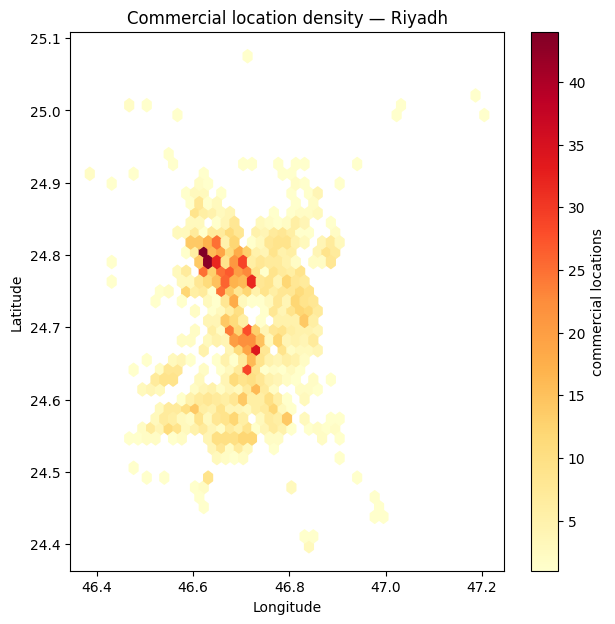

In [12]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(out['lng'], out['lat'], gridsize=45, mincnt=1, cmap='YlOrRd')
fig.colorbar(hb, label='commercial locations')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_title('Commercial location density — Riyadh')
plt.show()

## Step 10 — Download the files

In [ ]:
try:
    from google.colab import files
    files.download('heatmap_points.json')
    files.download('mullak_locations_integrated.csv')
    files.download('district_features.csv')
except ImportError:
    print('Files saved next to the notebook.')